BÀI 5 (Trang 29): Gom cụm khối u Breast Cancer (lành tính hay ác tính)

Cell 0: Import thư viện

In [1]:
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             silhouette_score, adjusted_rand_score)
from scipy.optimize import linear_sum_assignment

In [2]:
from google.colab import files
uploaded = files.upload()                 # chọn file breast+cancer+wisconsin+diagnostic.zip
ten_zip = list(uploaded.keys())[0]

with zipfile.ZipFile(ten_zip) as z:
    z.extractall('wdbc')
print(glob.glob('wdbc/*'))                # xem các file sau khi giải nén

Saving breast+cancer+wisconsin+diagnostic.zip to breast+cancer+wisconsin+diagnostic.zip
['wdbc/wdbc.names', 'wdbc/wdbc.data']


Bước 1: Đọc dữ liệu và đặt tên cột

In [3]:
print("Lê Anh Pha - 6451071056")

duong_dan = glob.glob('wdbc/*.data')[0]

ten_goc = ['radius', 'texture', 'perimeter', 'area', 'smoothness',
           'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
cot = (['id', 'diagnosis']
       + [f'{t}_mean' for t in ten_goc]
       + [f'{t}_se' for t in ten_goc]
       + [f'{t}_worst' for t in ten_goc])

df = pd.read_csv(duong_dan, header=None, names=cot)

print("Kích thước dữ liệu:", df.shape)
print(df.head())
print("\nSố giá trị thiếu:", df.isnull().sum().sum())
print("\nSố mẫu theo chẩn đoán (M = ác tính, B = lành tính):")
print(df['diagnosis'].value_counts())

Lê Anh Pha - 6451071056
Kích thước dữ liệu: (569, 32)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  

Bước 2: Tách đặc trưng và nhãn thật

In [4]:
print("Lê Anh Pha - 6451071056")

# Nhãn thật chỉ dùng để chấm điểm sau khi gom cụm, KHÔNG đưa vào k-Means
y_true = (df['diagnosis'] == 'M').astype(int)     # 1 = ác tính, 0 = lành tính
X = df.drop(columns=['id', 'diagnosis'])

print("X:", X.shape)
print("Dải giá trị của vài cột (để thấy các thuộc tính khác thang đo):")
print(X[['area_mean', 'smoothness_mean', 'fractal_dimension_mean']].describe().loc[['min', 'max']])

Lê Anh Pha - 6451071056
X: (569, 30)
Dải giá trị của vài cột (để thấy các thuộc tính khác thang đo):
     area_mean  smoothness_mean  fractal_dimension_mean
min      143.5          0.05263                 0.04996
max     2501.0          0.16340                 0.09744


Bước 3: Chuẩn hóa dữ liệu

In [5]:
print("Lê Anh Pha - 6451071056")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Trung bình sau chuẩn hóa (xấp xỉ 0):", np.round(X_scaled.mean(axis=0)[:5], 3))
print("Độ lệch chuẩn sau chuẩn hóa (xấp xỉ 1):", np.round(X_scaled.std(axis=0)[:5], 3))

Lê Anh Pha - 6451071056
Trung bình sau chuẩn hóa (xấp xỉ 0): [-0.  0. -0. -0. -0.]
Độ lệch chuẩn sau chuẩn hóa (xấp xỉ 1): [1. 1. 1. 1. 1.]


Bước 4: Elbow method (khảo sát số cụm)

Lê Anh Pha - 6451071056


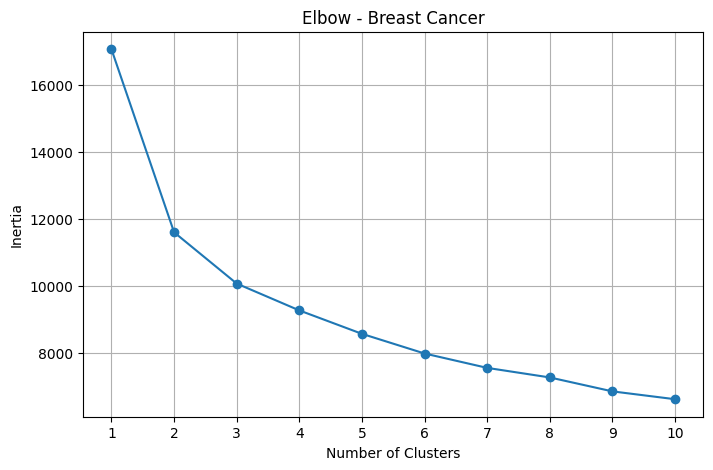

In [6]:
print("Lê Anh Pha - 6451071056")

inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, 'o-')
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Breast Cancer')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Bước 5: Gom cụm bằng k-Means (k = 2)

In [7]:
print("Lê Anh Pha - 6451071056")

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

print("Số điểm trong mỗi cụm:", np.bincount(clusters))
print(f"Silhouette coefficient: {silhouette_score(X_scaled, clusters):.4f}")

Lê Anh Pha - 6451071056
Số điểm trong mỗi cụm: [375 194]
Silhouette coefficient: 0.3434


Bước 6: Ghép cụm với nhãn và đánh giá

In [8]:
print("Lê Anh Pha - 6451071056")

# Bảng đối chiếu cụm với chẩn đoán thật
bang = pd.crosstab(clusters, df['diagnosis'], rownames=['Cụm'], colnames=['Chẩn đoán thật'])
print(bang)

# Ghép cụm -> nhãn bằng cách tối đa số mẫu khớp
cm_raw = confusion_matrix(clusters, y_true)
row_ind, col_ind = linear_sum_assignment(-cm_raw)
mapping = dict(zip(row_ind, col_ind))
print("\nGhép cụm -> nhãn (0 = lành tính, 1 = ác tính):", mapping)

y_pred = np.array([mapping[c] for c in clusters])

print(f"\nAccuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Adjusted Rand Index: {adjusted_rand_score(y_true, clusters):.4f}")
print("\nPrecision / Recall / F1-score:")
print(classification_report(y_true, y_pred, target_names=['Lành tính (B)', 'Ác tính (M)'], digits=4))

Lê Anh Pha - 6451071056
Chẩn đoán thật    B    M
Cụm                     
0               339   36
1                18  176

Ghép cụm -> nhãn (0 = lành tính, 1 = ác tính): {np.int64(0): np.int64(0), np.int64(1): np.int64(1)}

Accuracy: 0.9051
Adjusted Rand Index: 0.6536

Precision / Recall / F1-score:
               precision    recall  f1-score   support

Lành tính (B)     0.9040    0.9496    0.9262       357
  Ác tính (M)     0.9072    0.8302    0.8670       212

     accuracy                         0.9051       569
    macro avg     0.9056    0.8899    0.8966       569
 weighted avg     0.9052    0.9051    0.9042       569



Bước 7: Confusion matrix bằng heatmap

Lê Anh Pha - 6451071056


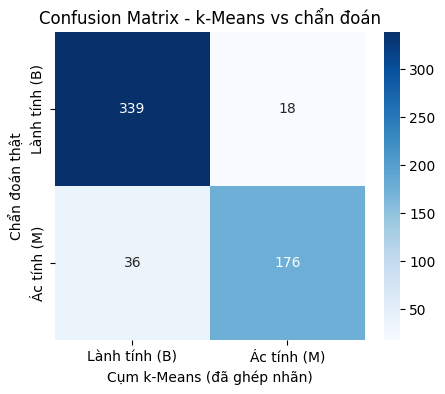

In [9]:
print("Lê Anh Pha - 6451071056")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Lành tính (B)', 'Ác tính (M)'],
            yticklabels=['Lành tính (B)', 'Ác tính (M)'])
plt.xlabel('Cụm k-Means (đã ghép nhãn)')
plt.ylabel('Chẩn đoán thật')
plt.title('Confusion Matrix - k-Means vs chẩn đoán')
plt.show()

Bước 8: Biểu diễn kết quả gom cụm bằng PCA 2 chiều

Lê Anh Pha - 6451071056
Tỷ lệ phương sai giữ lại: [0.443 0.19 ] | tổng: 0.632


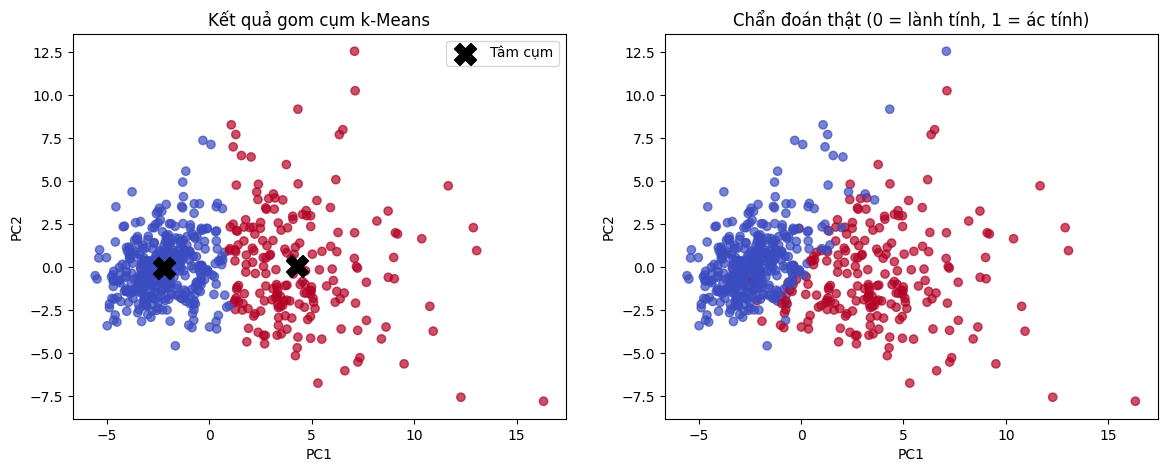

In [10]:
print("Lê Anh Pha - 6451071056")

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
print("Tỷ lệ phương sai giữ lại:", np.round(pca.explained_variance_ratio_, 3),
      "| tổng:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=clusters, cmap='coolwarm', alpha=0.7)
c2d = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(c2d[:, 0], c2d[:, 1], c='black', marker='X', s=250, label='Tâm cụm')
axes[0].set_title('Kết quả gom cụm k-Means')
axes[0].legend()

axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y_true, cmap='coolwarm', alpha=0.7)
axes[1].set_title('Chẩn đoán thật (0 = lành tính, 1 = ác tính)')

for ax in axes:
    ax.set_xlabel('PC1'), ax.set_ylabel('PC2')
plt.show()